In [1]:
#ruff: noqa: T201, T203
from __future__ import annotations

import os
from pathlib import Path

if Path.cwd().name == 'notebooks':
    os.chdir('..')

import logging
from dotenv import load_dotenv

from src.evaluate import (
    analyze_results,
    plot_usage_histograms,
    get_predictions_with_gt
)
from src.LLM_servers.openai import OpenAIServer
from src.onto_access import OntologyAccess
from src.onto_object import OntologyEntryAttr
from src.prompts.system import INITIALIZATION_MESSAGE
from src.prompts.prompts import *
from src.utils import (
    read_file,
    write_lines
)
from src.formatting import (
    format_oracle_pairs_filepath,
    format_confusion_matrix_filepath,
    format_oracle_predictions_filepath,
    format_run_path,
    format_from_run_path

)
from src.LLM_servers.openai import OpenAIServer

from config.config import DATA_DIR

from src.processing import (

    parallel_samples_process
)
from src.result_formatting import print_results_entry

logging.getLogger().setLevel(logging.WARNING)
load_dotenv()

%load_ext autoreload
%autoreload 2

In [2]:
llm_oracle = OpenAIServer()
llm_oracle.add_system_context(INITIALIZATION_MESSAGE)

In [3]:
DATASET_NAME = "anatomy"
SET_NAME = "human-mouse"
SOURCE_ONTOLOGY = "mouse"
TARGET_ONTOLOGY = "human"

src_onto_path = DATA_DIR / DATASET_NAME / SET_NAME / f"{SOURCE_ONTOLOGY}.owl"
tgt_onto_path = DATA_DIR / DATASET_NAME / SET_NAME / f"{TARGET_ONTOLOGY}.owl"

onto_src = OntologyAccess(src_onto_path, annotate_on_init=True)
onto_tgt = OntologyAccess(tgt_onto_path, annotate_on_init=True)

* Owlready2 * Creating new ontology human <data/anatomy/human-mouse/human.owl#>.
* Owlready2 * ADD TRIPLE data/anatomy/human-mouse/human.owl http://www.w3.org/1999/02/22-rdf-syntax-ns#type http://www.w3.org/2002/07/owl#Ontology
* Owlready2 *     ...loading ontology human from data/anatomy/human-mouse/human.owl...


* Owlready2 * Reseting property oboInOwl.ObsoleteProperty: new triples are now available.
* Owlready2 * Reseting property oboInOwl.hasRelatedSynonym: new triples are now available.
* Owlready2 * Reseting property oboInOwl.hasDefaultNamespace: new triples are now available.
* Owlready2 * Reseting property oboInOwl.savedBy: new triples are now available.
* Owlready2 * Reseting property oboInOwl.hasDate: new triples are now available.


* Owlready2 *     ...8 properties found: ObsoleteProperty, UNDEFINED_part_of, label, hasRelatedSynonym, hasDefaultNamespace, savedBy, hasDate, hasDefinition


In [4]:
# access the ontology entry example
entry_uri = "http://human.owl#NCI_C33075"
entry = OntologyEntryAttr(entry_uri, onto_tgt)

print(entry)
print(entry.get_all_entity_names())
print(entry.get_parents_preferred_names())
print(entry.get_children_preferred_names())
print(entry.get_synonyms())
print(entry.get_direct_parents())
print(entry.get_direct_parents().pop().get_direct_children())


{'class': human.NCI_C33075, 'uri': 'http://human.owl#NCI_C33075', 'preffered_names': {'Meibomian_Gland'}, 'synonyms': {'Meibomian Gland'}, 'all_names': {'Meibomian_Gland', 'Meibomian Gland'}, 'parents': {owl.Thing, human.NCI_C13018, human.NCI_C12219, human.NCI_C12712, human.NCI_C33519, human.NCI_C13319}, 'children': set()}
{'Meibomian_Gland', 'Meibomian Gland'}
[{owl.Thing}, {'Organ'}, {'Anatomic_Structure_System_or_Substance'}, {'Exocrine_Gland'}, {'Sebaceous_Gland'}, {'Gland'}]
[]
{'Meibomian Gland'}
{human.NCI_C33519}
{human.NCI_C33521, human.NCI_C33075}


Processing Lines prompt_only_names:   0%|          | 0/10 [00:00<?, ?it/s]

Processing Lines prompt_only_names: 100%|██████████| 10/10 [00:01<00:00,  5.65it/s]


Mean input tockens: 157.6
Mean output tockens: 6.0
Total input tockens: 1576
Total output tockens: 60


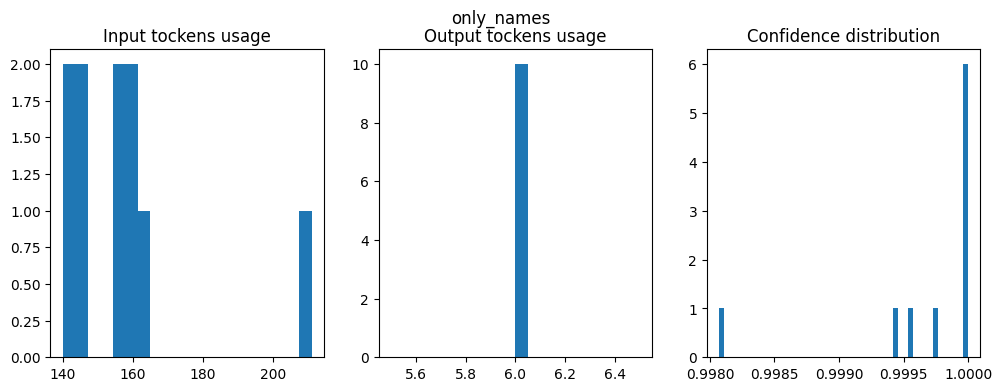

Accuracy: 0.60
Precision: 0.75
Recall: 0.75
F1 Score: 0.75


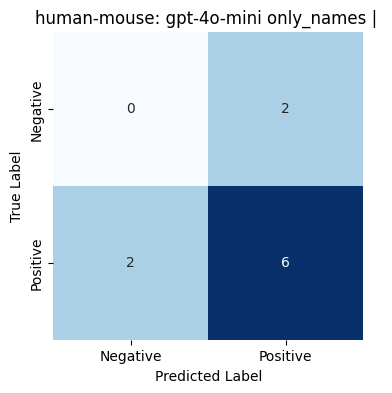

In [7]:
MAX_WORKERS = 6
MODEL = "gpt-4o-mini"


EXP_NAMES_TO_PROMPT_FUNCTIONS = {
    "only_names": prompt_only_names,
    "with_hierarchy": prompt_with_hierarchy,
    "only_with_parents": prompt_only_with_parents,
    "only_with_children": prompt_only_with_children,
    "synonyms_subsumption": prompt_synonyms_subsumption,
    "one_name_one_synonym": prompt_one_name_one_synonym,
}

candidates_save_path = format_oracle_pairs_filepath(DATASET_NAME, SET_NAME)
candidate_pairs_lines = read_file(candidates_save_path)[:10]

run_path = format_run_path()

for current_exp_name, prompt_function in EXP_NAMES_TO_PROMPT_FUNCTIONS.items():

    results, tokens_usage, confidences = parallel_samples_process(
        candidate_pairs_lines, llm_oracle, onto_src, onto_tgt, MODEL, MAX_WORKERS, prompt_function
    )
    plot_usage_histograms(tokens_usage, confidences, do_plot=True, do_print=True, suptitle=current_exp_name)

    
    prediction_path, stats_path, diagram_path = format_from_run_path(run_path, SET_NAME, MODEL, current_exp_name)
    
    write_lines(results, prediction_path)
    

    predictions = get_predictions_with_gt(run_path, DATASET_NAME, SET_NAME, MODEL, current_exp_name)
    
    analyze_results(
        predictions,
        print_results=True,
        plot_confusion_matrix=True,
        subtitle=f"{SET_NAME}: {MODEL} {current_exp_name} | ",
        cm_save_path=diagram_path,
        stats_path = stats_path
    )
    print("\n\n\n")
    break


Accuracy: 0.60
Precision: 0.75
Recall: 0.75
F1 Score: 0.75


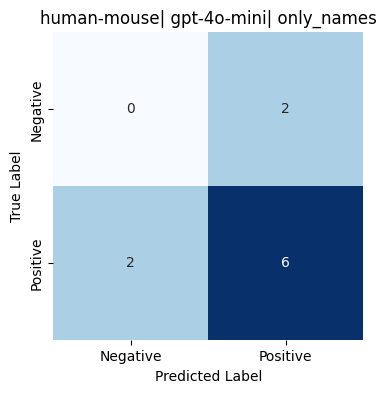

In [9]:
exp_name = "only_names"
predictions = get_predictions_with_gt(run_path,DATASET_NAME, SET_NAME, MODEL, exp_name)
analyze_results(
    predictions, print_results=True, plot_confusion_matrix=True, subtitle=f"{SET_NAME}| {MODEL}| {exp_name}"
);

In [11]:
exp_name = "only_names"
res_df = get_predictions_with_gt(run_path,DATASET_NAME, SET_NAME, model='gpt-4o-mini', exp_name=exp_name)

In [12]:
res_df

,Source,Target,Prediction,Confidence,Label,Type
0,http://human.owl#NCI_C33748,http://mouse.owl#MA_0001221,True,0.999999,True,TP
1,http://human.owl#NCI_C12262,http://mouse.owl#MA_0001615,True,0.999739,True,TP
2,http://human.owl#NCI_C32658,http://mouse.owl#MA_0002684,False,0.999569,True,FN
3,http://human.owl#NCI_C53050,http://mouse.owl#MA_0002234,True,0.999998,False,FP
4,http://human.owl#NCI_C33743,http://mouse.owl#MA_0002390,False,0.998073,True,FN
5,http://human.owl#NCI_C33075,http://mouse.owl#MA_0001249,True,0.999999,True,TP
6,http://human.owl#NCI_C32497,http://mouse.owl#MA_0000451,True,0.999999,True,TP
7,http://human.owl#NCI_C33627,http://mouse.owl#MA_0001460,True,0.999447,False,FP
8,http://human.owl#NCI_C33791,http://mouse.owl#MA_0000777,True,0.999987,True,TP
9,http://human.owl#NCI_C12909,http://mouse.owl#MA_0002434,True,0.999998,True,TP


In [13]:
print_results_entry(res_df, onto_tgt, onto_src, pair_type='FN', idx=0)

Processing pair 0 of type FN
'Source Entry:\n'
{'all_names': {'Gastric Muscularis Mucosa', 'Gastric_Muscularis_Mucosa'},
 'children': set(),
 'class': human.NCI_C32658,
 'parents': {human.NCI_C13166,
             owl.Thing,
             human.NCI_C21599,
             human.NCI_C12219,
             human.NCI_C33177,
             human.NCI_C12749,
             human.NCI_C33904,
             human.NCI_C12801,
             human.NCI_C32918,
             human.NCI_C33149,
             human.NCI_C32664,
             human.NCI_C32656},
 'preffered_names': {'Gastric_Muscularis_Mucosa'},
 'synonyms': {'Gastric Muscularis Mucosa'},
 'uri': 'http://human.owl#NCI_C32658'}
'Target Entry:\n'
{'all_names': {'stomach muscularis mucosa'},
 'children': set(),
 'class': mouse.MA_0002684,
 'parents': {owl.Thing},
 'preffered_names': {'stomach muscularis mucosa'},
 'synonyms': {},
 'uri': 'http://mouse.owl#MA_0002684'}
Parent of Source Concept: [{owl.Thing}, {'Lamina_Propria'}, {'Normal_Tissue'}, {'Gastric